In [190]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

In [22]:
df = pd.read_csv('数据.csv')
missing = df.isna()
AllGood = ~missing.any(axis=1)
df_AllGood = df[AllGood]

HasMissing = missing.any(axis=1)
df_HasMissing = df[HasMissing]

print("df全部行数：",len(df))
print("df无缺失值行数：",len(df_AllGood))
print("df有缺失值行数：",len(df_HasMissing))

pctMissing = missing["pct_rate"] & (missing.sum(axis=1) == 1)
df_pctMissing = df.loc[pctMissing]
print("pct_rate缺失行数：",len(df_pctMissing))

TwoMoreMissing = missing.sum(axis=1) >= 2
df_TwoMoreMissing = df.loc[TwoMoreMissing]
print("大于等于两个缺失值行数：",len(df_TwoMoreMissing))

df全部行数： 7100847
df无缺失值行数： 6192773
df有缺失值行数： 908074
pct_rate缺失行数： 1582
大于等于两个缺失值行数： 906492


In [31]:
df_TwoMoreMissing.isna().sum(axis=1).value_counts()
# 发现缺失值>=2的情况只有4、5个缺失值，那么df只会存在1、4、5个缺失值的情况
# 缺失1个的情况如上通过加和发现全部为pct_rate缺失
# 因此后续先考虑缺失4、5个的情况

5    886521
4     19971
Name: count, dtype: int64

In [61]:
Missing_count = df.isna().sum(axis=1)
df_Missing4 = df[Missing_count == 4]
df_Missing5 = df[Missing_count == 5]

df_Missing4[["order_book_id", "date",'pct_rate']].isna().sum()

TradeCols4 = ["buy_volume", "buy_value", "sell_volume", "sell_value"]

check1 = (
    df_Missing4[["order_book_id", "date", "pct_rate"]].notna().all(axis=1)
    & df_Missing4[TradeCols4].isna().all(axis=1)
)
print("缺4数据行全为4个买卖列缺失",check1.all())

df_Missing5[["order_book_id", "date"]].isna().sum()

TradeCols5 = ["buy_volume", "buy_value", "sell_volume", "sell_value", "pct_rate"]
check2 = (
    df_Missing5[["order_book_id", "date"]].notna().all(axis=1)
    & df_Missing5[TradeCols5].isna().all(axis=1)
)
print("缺5数据行全为4个买卖列+pct_rate列缺失",check2.all())

缺4数据行全为4个买卖列缺失 True
缺5数据行全为4个买卖列+pct_rate列缺失 True


In [134]:
TradeCols4 = ["buy_volume", "buy_value", "sell_volume", "sell_value"]
df_Sorted = df.sort_values(["order_book_id", "date"], ascending=[True, True])

TradeMissing = df_Sorted[TradeCols4].isna().all(axis=1)
TradeValid = df_Sorted[TradeCols4].notna().all(axis=1)

ValidBeforeCount = (
    TradeValid
    .groupby(df_Sorted["order_book_id"]).cumsum()
    .groupby(df_Sorted["order_book_id"]).shift(fill_value=0)
) # 累积计数每组股票内 前方行的valid数目
hasValidBefore = ValidBeforeCount > 0

ValidAfterCount = (
    TradeValid.iloc[::-1]
    .groupby(df_Sorted["order_book_id"].iloc[::-1]).cumsum()
    .groupby(df_Sorted["order_book_id"].iloc[::-1]).shift(fill_value=0)
) # 累积计数每组股票内 后方行的valid数目 使用倒转方式
hasValidAfter = ValidAfterCount.iloc[::-1] > 0

MissingBetween = TradeMissing & hasValidBefore & hasValidAfter # 三组bool叠加判断
MissingAtStart = TradeMissing & ~hasValidBefore
MissingAtEnd = TradeMissing & ~hasValidAfter

print("队首缺失行数：", MissingAtStart.sum())
print("有效记录之间的缺失行数：", MissingBetween.sum())
print("队末缺失行数：", MissingAtEnd.sum())

print("总计：",(MissingAtStart.sum()+MissingBetween.sum()+MissingAtEnd.sum()) )
# 总计值与 “大于等于两个缺失值行数： 906492” 相等，那么我们猜测三类统计规则不会有交集
# 确切地方法如下：
MissingCategoryCount = (
    MissingAtStart.astype(int)
    + MissingBetween.astype(int)
    + MissingAtEnd.astype(int)
)
print("缺失类别计数：\n",MissingCategoryCount.value_counts().sort_index())
# 将三类判断分别计数，若有>1则表示交集部分
# 结果表明确实不会有交集，三类互斥且完备，缺失4、5数据行会处于每支股票队首、队末以及有效行中间。

队首缺失行数： 783555
有效记录之间的缺失行数： 14465
队末缺失行数： 108472
总计： 906492
缺失类别计数：
 0    6194355
1     906492
Name: count, dtype: int64


In [135]:
df_Sorted.groupby("order_book_id")["pct_rate"].apply(
    lambda s: s.isna().iloc[0]
).value_counts()
# 与猜测相符，缺失1数据 即仅pct_rate缺失的行 处于每只股票队首。

pct_rate
False    3761
True     1582
Name: count, dtype: int64

In [151]:
FactorUsable = (
    df_Sorted["pct_rate"].notna()
    & df_Sorted["buy_value"].notna()
    & df_Sorted["sell_value"].notna()
)

FactorValid20d = (
    FactorUsable
    .groupby(df_Sorted["order_book_id"]).transform(lambda temp: temp.rolling(window=20, min_periods=1).sum())
)

RowInStock = df_Sorted.groupby("order_book_id").cumcount() + 1 # 队内排序
FullWindows = RowInStock >= 20

WindowValidCount = FactorValid20d.loc[FullWindows].astype(int) # 排除前19有效行
print("各有效样本数对应的窗口数量：")
print(WindowValidCount.value_counts().sort_index())


各有效样本数对应的窗口数量：
0      863576
1        2001
2        2029
3        2057
4        2048
5        2061
6        2090
7        2065
8        2100
9        2134
10       6064
11       3367
12       3289
13       3129
14       3736
15       7060
16       4373
17       4678
18       5821
19      28937
20    6046715
Name: count, dtype: int64


In [178]:
print("完整窗口总数：", len(WindowValidCount))
print("有效样本数 >= 19 的窗口数：", (WindowValidCount >= 19).sum())
print("有效样本数 >= 19 的占比：", (WindowValidCount >= 19).mean())
print("有效样本数 < 19 的窗口数：", (WindowValidCount < 19).sum())
print("有效数为 0 的窗口：", (WindowValidCount == 0).sum())
print("有效数为 1–18 的占比：", WindowValidCount.between(1, 18).mean())
# 可见有效数为0、19、20的占比高达0.991，考虑把准入门槛设置为19有效数，另外我们研究一下有效数为0的窗口情况。

完整窗口总数： 6999330
有效样本数 >= 19 的窗口数： 6075652
有效样本数 >= 19 的占比： 0.868033368908167
有效样本数 < 19 的窗口数： 923678
有效数为 0 的窗口： 863576
有效数为 1–18 的占比： 0.008586821881522946


In [161]:
WindowStats = df_Sorted[["order_book_id", "date"]].copy()
WindowStats["ValidCount"] = FactorValid20d
WindowStats["RowInStock"] = RowInStock

# 每只股票只看完整20日窗口
WindowStats = WindowStats.loc[WindowStats["RowInStock"] >= 20].copy()

# 有效窗口：窗口内至少有1个可用样本
WindowStats["HasValid"] = WindowStats["ValidCount"] > 0

by_stock = WindowStats["order_book_id"]

# 当前窗口之前是否出现过有效窗口
WindowStats["HasValidBefore"] = (
    WindowStats["HasValid"]
    .groupby(by_stock)
    .cumsum()
    .groupby(by_stock)
    .shift(fill_value=0)
    .gt(0)
)

# 当前窗口之后是否出现过有效窗口
reverse_stock = by_stock.iloc[::-1]
WindowStats["HasValidAfter"] = (
    WindowStats["HasValid"].iloc[::-1]
    .groupby(reverse_stock)
    .cumsum()
    .groupby(reverse_stock)
    .shift(fill_value=0)
    .iloc[::-1]
    .gt(0)
)

ZeroWindows = WindowStats.loc[WindowStats["ValidCount"] == 0].copy()

# 零有效窗口只出现在有效窗口之前：队首
ZeroWindows["AtStart"] = ~ZeroWindows["HasValidBefore"]

# 零有效窗口只出现在有效窗口之后：队末
ZeroWindows["AtEnd"] = ~ZeroWindows["HasValidAfter"]

# 前后都出现过有效窗口：队中
ZeroWindows["InMiddle"] = (
    ZeroWindows["HasValidBefore"] & ZeroWindows["HasValidAfter"]
)

print("队首零有效窗口数：", ZeroWindows["AtStart"].sum())
print("队中零有效窗口数：", ZeroWindows["InMiddle"].sum())
print("队末零有效窗口数：", ZeroWindows["AtEnd"].sum())

队首零有效窗口数： 754961
队中零有效窗口数： 3863
队末零有效窗口数： 104752


In [162]:
# 当前窗口是否为零有效
IsZero = WindowStats["ValidCount"].eq(0)

# 如果当前是零、前一个不是零（或当前是该股票第一行），就是一个零窗口块的起点
PreviousIsZero = (
    IsZero.groupby(WindowStats["order_book_id"])
    .shift(fill_value=False) # 首行默认False
)

ZeroBlockStart = IsZero & ~PreviousIsZero

# 统计每只股票零窗口块的数量
ZeroBlockCount = (
    ZeroBlockStart.groupby(WindowStats["order_book_id"])
    .sum()
)

print("有零有效窗口的股票数：", (ZeroBlockCount > 0).sum())
print("零窗口分成1块的股票数：", (ZeroBlockCount == 1).sum())
print("零窗口分成多块的股票数：", (ZeroBlockCount > 1).sum())
print("每只股票零窗口块数分布：")
print(ZeroBlockCount.value_counts().sort_index().to_string())

有零有效窗口的股票数： 1782
零窗口分成1块的股票数： 1690
零窗口分成多块的股票数： 92
每只股票零窗口块数分布：
ValidCount
0    3561
1    1690
2      86
3       6


In [ ]:
# 小结：按照门槛19有效行作为窗口滚动，其中0、19、20有效行的占比高达0.991，分析了0有效行的情况，大多在队首、队末，且大部分成块 1690 支，仅有92支股票有2或3块，因此对于0有效行的情况，虽然有863576个窗口数，但是实际真正有效的窗口非常少，因此我们可以仅对19、20有效行窗口进行滚动。另外，由于仅缺失1个数据的行全部是pct_rate缺失，且全部位于队首，因此不做额外考虑。

In [165]:
# 计算a
df_Sorted["a"] = (
    (df_Sorted["buy_value"] - df_Sorted["sell_value"])
    / (df_Sorted["buy_value"] + df_Sorted["sell_value"])
)
print("a 缺失行数：", df_Sorted["a"].isna().sum())
print(
    "买卖金额之和为0的行数：",
    (df_Sorted["buy_value"] + df_Sorted["sell_value"]).eq(0).sum()
)# 额外检查是否有分母为0的情况，防止错误

a 缺失行数： 906492
买卖金额之和为0的行数： 0


In [173]:
df_Sorted = df_Sorted.reset_index(drop=True)
FactorActive = (
    df_Sorted["pct_rate"].notna()
    & df_Sorted["a"].notna()
)
Factor = np.full(len(df_Sorted), np.nan) # 初始Factor数组 初始值nan
for _, positions in df_Sorted.groupby("order_book_id", sort=False).indices.items():
    returns = df_Sorted.loc[positions, "pct_rate"].to_numpy()
    a_values = df_Sorted.loc[positions, "a"].to_numpy()

    # 每一行对应一个连续20个原始交易日的窗口
    return_windows = sliding_window_view(returns, 20)
    a_windows = sliding_window_view(a_values, 20)
    valid_windows = sliding_window_view(
        FactorUsable.iloc[positions].to_numpy(), 20
    )

    valid_count = valid_windows.sum(axis=1)

    # 缺失收益率不参与排序；有效样本数不到19的窗口不计算
    sort_returns = np.where(valid_windows, return_windows, np.inf)
    lowest_four = np.argsort(sort_returns, axis=1)[:, :4]

    lowest_a = np.take_along_axis(a_windows, lowest_four, axis=1)
    window_factor = lowest_a.mean(axis=1)
    window_factor[valid_count < 19] = np.nan

    # 窗口结果对应每只股票从第20行开始的各行
    Factor[positions[19:]] = window_factor

df_Sorted["factor"] = Factor

In [174]:
print("factor 非缺失行数：", df_Sorted["factor"].notna().sum())
print("factor 缺失行数：", df_Sorted["factor"].isna().sum())

factor 非缺失行数： 6075652
factor 缺失行数： 1025195


In [180]:
df_Sorted.head(20)

,order_book_id,date,buy_volume,buy_value,sell_volume,sell_value,pct_rate,a,factor
0,000001.XSHE,2020-01-02,84209533.0,1.414344e+09,68813654.0,1.156852e+09,0.025532,0.100145,NaN
1,000001.XSHE,2020-01-03,57934985.0,9.936956e+08,53684496.0,9.207999e+08,0.018376,0.038076,NaN
2,000001.XSHE,2020-01-06,42854402.0,7.352786e+08,43353948.0,7.426516e+08,-0.006403,-0.004989,NaN
3,000001.XSHE,2020-01-07,40404529.0,6.915981e+08,32456227.0,5.554490e+08,0.004687,0.109177,NaN
4,000001.XSHE,2020-01-08,37420066.0,6.281692e+08,47362346.0,7.954396e+08,-0.028571,-0.117497,NaN
5,000001.XSHE,2020-01-09,51455388.0,8.608370e+08,51708277.0,8.644898e+08,0.007803,-0.002117,NaN
6,000001.XSHE,2020-01-10,28376473.0,4.726706e+08,30178372.0,5.024842e+08,-0.005956,-0.030573,NaN
7,000001.XSHE,2020-01-13,43810836.0,7.381023e+08,43402500.0,7.301694e+08,0.017975,0.005403,NaN
8,000001.XSHE,2020-01-14,63265983.0,1.075991e+09,67183383.0,1.141618e+09,-0.013537,-0.029594,NaN
9,000001.XSHE,2020-01-15,40288714.0,6.679568e+08,45655198.0,7.569325e+08,-0.014320,-0.062444,NaN


In [177]:
# 1025195行factor缺失，其中923678行是0-18有效行窗口导致的factor缺失（未达19门槛不进行计算），另外101517行是由于所以股票的前19行还未到达20日滚动窗口，因此101517 = 19 * 5343，所以目前结果对齐符合预期。

In [181]:
# 随机抽一条 factor 非缺失的记录
sample = df_Sorted.loc[df_Sorted["factor"].notna()].sample(
    1, random_state=42
).iloc[0]

row_pos = sample.name

# 取这条记录及其之前19行，共20个交易日
window = df_Sorted.iloc[row_pos - 19 : row_pos + 1].copy()

# 只保留 pct_rate 和 a 都有效的行
valid_window = window.dropna(subset=["pct_rate", "a"])

# 从有效行中找收益率最低的 ceil(有效数 × 20%) 天
n_low = int(np.ceil(len(valid_window) * 0.2))
lowest_days = valid_window.nsmallest(n_low, "pct_rate")

# 手动计算因子
manual_factor = lowest_days["a"].mean()

print("股票：", sample["order_book_id"])
print("窗口末日：", sample["date"])
print("窗口有效样本数：", len(valid_window))
print("低收益日数量：", n_low)
print("最低收益日及对应 a：")
print(lowest_days[["date", "pct_rate", "a"]])
print("手动计算 factor：", manual_factor)
print("代码计算 factor：", sample["factor"])
print("两者是否接近：", np.isclose(manual_factor, sample["factor"]))

股票： 600007.XSHG
窗口末日： 2024-05-08
窗口有效样本数： 20
低收益日数量： 4
最低收益日及对应 a：
               date  pct_rate         a
3970760  2024-04-16 -0.024464  0.044756
3970754  2024-04-08 -0.020554 -0.077567
3970764  2024-04-22 -0.012039 -0.120767
3970773  2024-05-08 -0.011858 -0.130191
手动计算 factor： -0.07094203844861362
代码计算 factor： -0.07094203844861362
两者是否接近： True


In [ ]:
# -------

In [183]:
df_Sorted["forward_return"] = (
    df_Sorted.groupby("order_book_id")["pct_rate"].shift(-1)
)
def calc_daily_ic(day):
    data = day.dropna(subset=["factor", "forward_return"])

    # 至少要有两个样本，且因子和收益都存在差异，相关系数才有意义
    if (
        len(data) < 2
        or data["factor"].nunique() < 2
        or data["forward_return"].nunique() < 2
    ):
        return np.nan

    return data["factor"].corr(data["forward_return"], method="spearman")


DailyIC = (
    df_Sorted.groupby("date")
    .apply(calc_daily_ic)
    .dropna()
)

print("有效 IC 交易日数：", len(DailyIC))
print("平均 Spearman IC：", DailyIC.mean())
print("IC 标准差：", DailyIC.std())
print("ICIR：", DailyIC.mean() / DailyIC.std())

有效 IC 交易日数： 1309
平均 Spearman IC： -0.0183793909832405
IC 标准差： 0.09779903957080256
ICIR： -0.18793017870011453


In [184]:
print("数据中的唯一日期数：", df_Sorted["date"].nunique())
print("有 IC 的日期数：", len(DailyIC))

AllDates = pd.Index(df_Sorted["date"].unique())
MissingICDates = AllDates.difference(DailyIC.index)

print("没有 IC 的日期数：", len(MissingICDates))
print(MissingICDates.sort_values())

数据中的唯一日期数： 1329
有 IC 的日期数： 1309
没有 IC 的日期数： 20
Index(['2020-01-02', '2020-01-03', '2020-01-06', '2020-01-07', '2020-01-08',
       '2020-01-09', '2020-01-10', '2020-01-13', '2020-01-14', '2020-01-15',
       '2020-01-16', '2020-01-17', '2020-01-20', '2020-01-21', '2020-01-22',
       '2020-01-23', '2020-02-03', '2020-02-04', '2020-02-05', '2025-06-30'],
      dtype='str')


In [186]:
GroupData = df_Sorted.dropna(
    subset=["factor", "forward_return"]
).copy()

# 每个交易日内按 factor 排名，再分成5组
RankPct = GroupData.groupby("date")["factor"].rank(
    method="first",
    pct=True
)

GroupData["FactorGroup"] = np.ceil(RankPct * 5).astype(int)
GroupDailyReturn = (
    GroupData.groupby(["date", "FactorGroup"])["forward_return"]
    .mean()
    .unstack()
)

print("各因子组的平均次日收益：")
print(GroupDailyReturn.mean().to_string())

各因子组的平均次日收益：
FactorGroup
1    0.000471
2    0.000731
3    0.000668
4    0.000490
5    0.000370


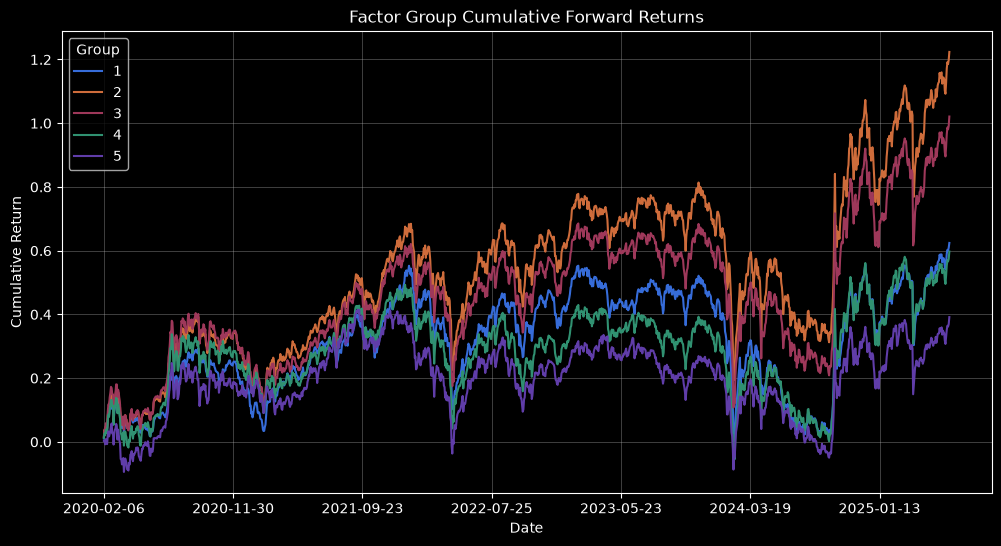

In [187]:
import matplotlib.pyplot as plt

GroupCumulativeReturn = (1 + GroupDailyReturn.fillna(0)).cumprod() - 1

GroupCumulativeReturn.plot(figsize=(12, 6))
plt.title("Factor Group Cumulative Forward Returns")
plt.xlabel("Date")
plt.ylabel("Cumulative Return")
plt.legend(title="Group")
plt.grid(True)
plt.show()

平均每日 G1-G5 收益差： 0.00010032091318533032


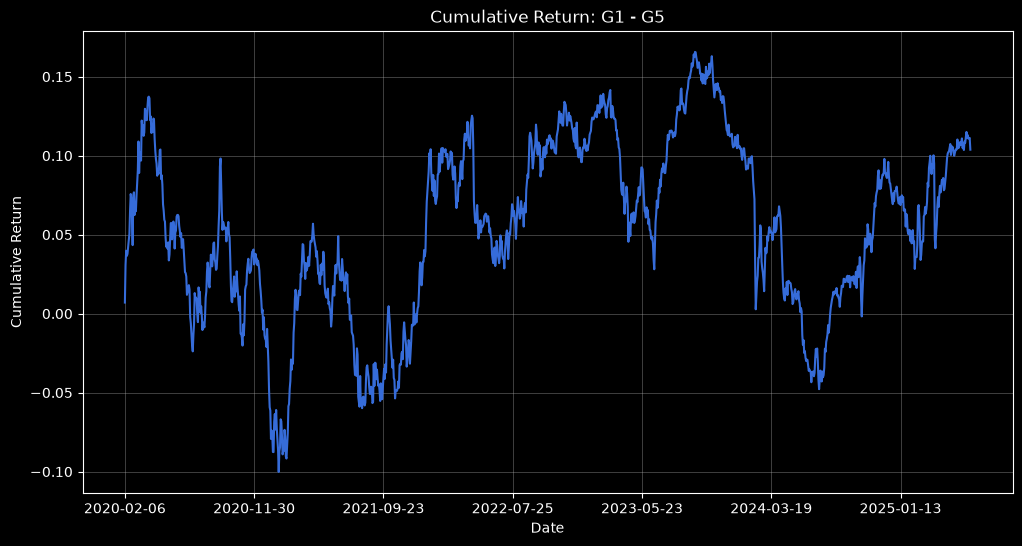

In [188]:
# 每日多 G1、空 G5 的收益差
LongShortReturn = GroupDailyReturn[1] - GroupDailyReturn[5]

# 累计收益
LongShortCumulative = (1 + LongShortReturn).cumprod() - 1

print("平均每日 G1-G5 收益差：", LongShortReturn.mean())

LongShortCumulative.plot(figsize=(12, 6))
plt.title("Cumulative Return: G1 - G5")
plt.xlabel("Date")
plt.ylabel("Cumulative Return")
plt.grid(True)
plt.show()

In [ ]:
'''
总结：

方法
- 按股票和日期排序，需要保留缺失行在原始交易日序列中的位置。
- 计算主动买卖因子：a = (buy_value - sell_value) / (buy_value + sell_value)。
- 每只股票按最近 20 个原始交易日滚动；只使用 pct_rate 和 a 都有效的行。有效样本数至少为 19 时，取收益率最低的 20%（19 或 20 个有效样本时都是 4 天），对这几天的 a 求平均作为 factor。
- 用 t 日 factor 对齐 t+1 日收益，计算每日 Spearman IC；再按每天的因子值分成 5 组，比较次日收益。

结果
- 完整 20 日窗口共 6,999,330 个；其中 6,075,652 个达到至少 19 个有效样本并计算了因子。
- 有效 IC 的交易日有 1,309 天；平均 Spearman IC 为 −0.0184，ICIR 为 −0.188，整体呈轻微负向关系。
- 分组平均次日收益从 G1 到 G5 分别为 0.0471%、0.0731%、0.0668%、0.0490%、0.0370%。G5 最低，但各组没有严格单调排列。
- G1−G5 平均每日收益差约 0.0100%，累计曲线最终约 +11%，但期间波动明显。

结论与限制
样本内结果显示因子有一定负向倾向：高因子组整体弱于低因子组，但 IC 较小，分组收益也不单调，暂时不能称为稳定的预测信号。分组组合按日等权计算，尚未计入交易成本，也没有做风险中性化或显著性检验。
另外，19 个有效样本的门槛是基于窗口规则选定的分析口径；它表示每个 20 日窗口最多容忍 1 个无效观测，这基于主观设定，也可以改变门槛多次尝试分析。


'''

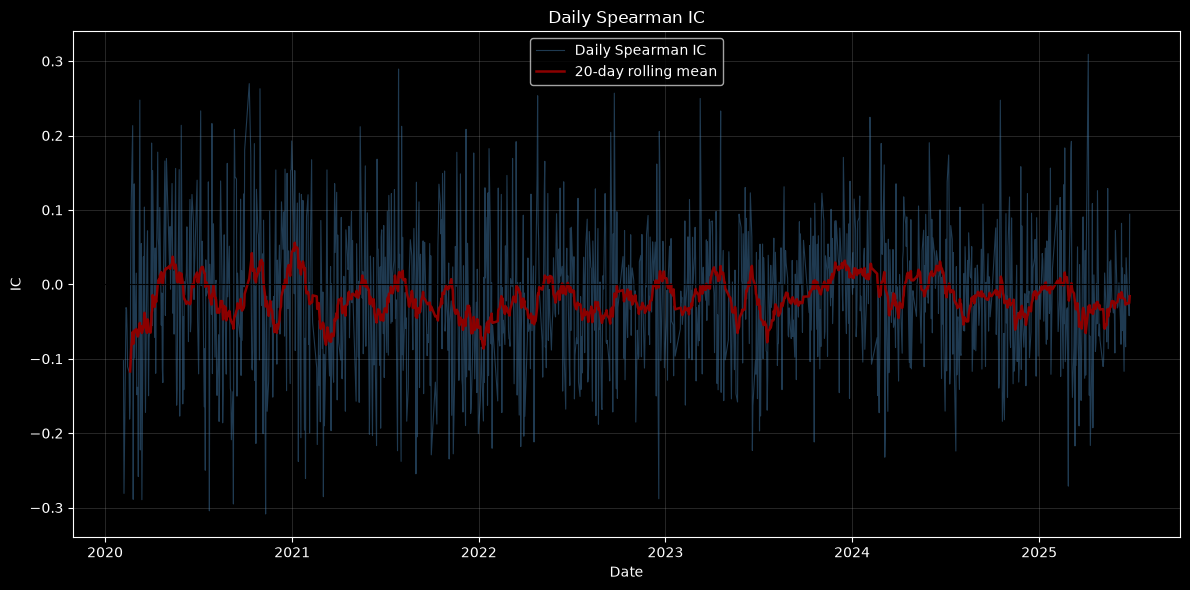

In [192]:
# 确保日期索引能用于绘图
ICPlot = DailyIC.copy()
ICPlot.index = pd.to_datetime(ICPlot.index)
ICPlot = ICPlot.sort_index()

# 20个有效IC交易日的滚动均值
ICRollingMean = ICPlot.rolling(window=20, min_periods=10).mean()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    ICPlot.index,
    ICPlot,
    color="steelblue",
    alpha=0.45,
    linewidth=0.8,
    label="Daily Spearman IC"
)
ax.plot(
    ICRollingMean.index,
    ICRollingMean,
    color="darkred",
    linewidth=1.8,
    label="20-day rolling mean"
)
ax.axhline(0, color="black", linewidth=0.8)

ax.set_title("Daily Spearman IC")
ax.set_xlabel("Date")
ax.set_ylabel("IC")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("IC分析图.png", dpi=160)
plt.show()